In [1]:
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

from src.data import load_data, deduplicate, split_X_y, FEATURE_COLS, CLASS_ORDER, SEED, RESULTS_DIR
from src.models import Model, MODEL_NAMES
from src.evaluation import fit_evaluate, evaluate, summarize
from src.plotting import use_style, save, heatmap, SEQUENTIAL, MODEL_COLORS, MODEL_MARKERS, TEXT_MUTED

use_style()
train, test = load_data()
X, y = split_X_y(deduplicate(train))
X_test, y_test = split_X_y(test)
params = json.loads((RESULTS_DIR / "02_selected_params.json").read_text())
folds = list(StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED).split(X, y))
METRICS = ["macro_f1", "balanced_accuracy", "accuracy", "macro_precision", "roc_auc", "brier", "ece",
           "detection_rate", "false_alarm_rate", "fit_s", "predict_ms_per_1k"]
print(X.shape, X_test.shape)

(107740, 42) (82332, 42)


In [2]:
rows, oof = [], {}
for name in MODEL_NAMES:
    oof[name] = np.empty(len(y), dtype=int)
    for fold, (tr, va) in enumerate(folds):
        scores, _, proba = fit_evaluate(Model(name, params[name]), X.iloc[tr], y[tr], X.iloc[va], y[va])
        oof[name][va] = proba.argmax(axis=1)
        rows.append({"model": name, "fold": fold, **scores})
    print(name, round(np.mean([r["macro_f1"] for r in rows if r["model"] == name]), 4))
cv = pd.DataFrame(rows)
cv.to_csv(RESULTS_DIR / "03_cv_folds.csv", index=False)
pd.DataFrame(oof).assign(y_true=y).to_csv(RESULTS_DIR / "03_cv_oof_predictions.csv", index=False)

Dummy 0.065


LogReg 0.458


kNN 0.4882


NaiveBayes 0.2273


RandomForest 0.6153


XGBoost 0.6284


In [3]:
cv_summary = summarize(cv, "model", METRICS)
cv_summary.to_csv(RESULTS_DIR / "03_cv_summary.csv")
best = cv_summary.drop("Dummy")["macro_f1_mean"].idxmax()
print(best)
cv_summary[[f"{m}_mean" for m in METRICS]].round(4)

XGBoost


,macro_f1_mean,balanced_accuracy_mean,accuracy_mean,macro_precision_mean,roc_auc_mean,brier_mean,ece_mean,detection_rate_mean,false_alarm_rate_mean,fit_s_mean,predict_ms_per_1k_mean
model,,,,,,,,,,,
Dummy,0.0650,0.1000,0.4816,0.0482,0.5000,1.0368,0.5184,0.0000,0.0000,0.4095,3.3349
LogReg,0.4580,0.6191,0.6874,0.4680,0.9466,0.3918,0.0752,0.9980,0.1998,151.9811,8.6449
kNN,0.4882,0.4734,0.7763,0.5628,0.7911,0.3091,0.0635,0.9222,0.0860,0.6084,705.4688
NaiveBayes,0.2273,0.4082,0.4776,0.3185,0.8375,1.0320,0.5134,0.9784,0.2615,1.0962,19.5791
RandomForest,0.6153,0.6447,0.8000,0.6098,0.8695,0.2727,0.0467,0.9912,0.1561,51.2421,35.3197
XGBoost,0.6284,0.6935,0.7948,0.6103,0.9727,0.2614,0.0518,0.9930,0.1637,65.5091,36.8201


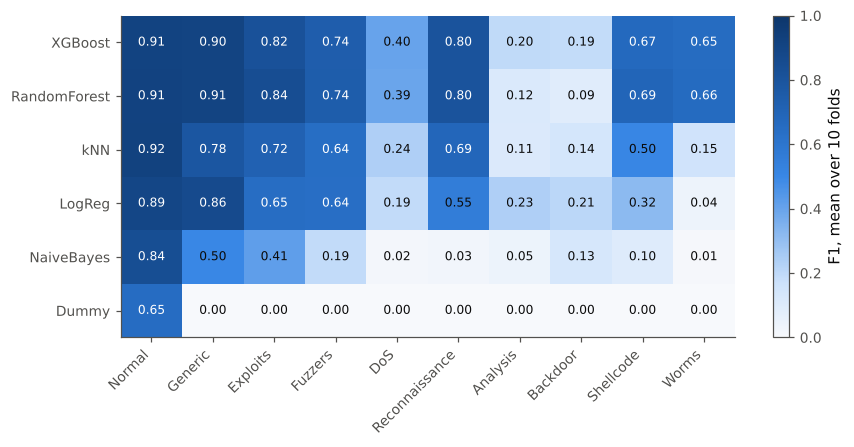

In [4]:
per_class_cv = cv.groupby("model", sort=False)[[f"f1_{c}" for c in CLASS_ORDER]].mean()
per_class_cv.columns = CLASS_ORDER
per_class_cv.to_csv(RESULTS_DIR / "03_cv_per_class_f1.csv")
order = cv_summary["macro_f1_mean"].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 3.8))
image = heatmap(ax, per_class_cv.loc[order].to_numpy(), SEQUENTIAL, 0, 1, xlabels=CLASS_ORDER, ylabels=order)
fig.colorbar(image, ax=ax, label="F1, mean over 10 folds")
save(fig, "03_cv_per_class_f1.png")
plt.show()

In [5]:
seen = X_test.merge(X.drop_duplicates().assign(seen=True), how="left", on=FEATURE_COLS)["seen"].notna().to_numpy()
test_rows, test_proba, test_cm = [], {}, {}
for name in MODEL_NAMES:
    scores, cm, proba = fit_evaluate(Model(name, params[name]), X, y, X_test, y_test)
    unseen_scores, _ = evaluate(y_test[~seen], proba[~seen])
    test_rows.append({"model": name, **scores, "macro_f1_unseen_rows": unseen_scores["macro_f1"]})
    test_proba[name], test_cm[name] = proba, cm
    pd.DataFrame(cm, index=CLASS_ORDER, columns=CLASS_ORDER).to_csv(RESULTS_DIR / f"03_test_confusion_{name}.csv")
test_scores = pd.DataFrame(test_rows).set_index("model")
test_scores.to_csv(RESULTS_DIR / "03_test_scores.csv")
print(round(seen.mean(), 4))
test_scores[METRICS + ["macro_f1_unseen_rows"]].round(4)

0.1037


,macro_f1,balanced_accuracy,accuracy,macro_precision,roc_auc,brier,ece,detection_rate,false_alarm_rate,fit_s,predict_ms_per_1k,macro_f1_unseen_rows
model,,,,,,,,,,,,
Dummy,0.0620,0.1000,0.4494,0.0449,0.5000,1.1012,0.5506,0.0000,0.0000,0.4480,2.0672,0.0650
LogReg,0.3507,0.5699,0.6159,0.3910,0.9354,0.4799,0.1602,0.9974,0.4231,156.9947,3.5645,0.3844
kNN,0.4280,0.4515,0.7303,0.4750,0.8244,0.3913,0.1222,0.9573,0.2500,0.5385,715.8948,0.4514
NaiveBayes,0.2332,0.4170,0.5107,0.3180,0.8499,0.9658,0.4812,0.9841,0.4644,1.1112,27.4106,0.2515
RandomForest,0.5200,0.6331,0.6879,0.5464,0.9072,0.4078,0.1471,0.9950,0.3866,59.1862,25.3619,0.5553
XGBoost,0.5152,0.6509,0.6784,0.5348,0.9565,0.4165,0.1675,0.9961,0.3964,74.6939,38.1613,0.5486


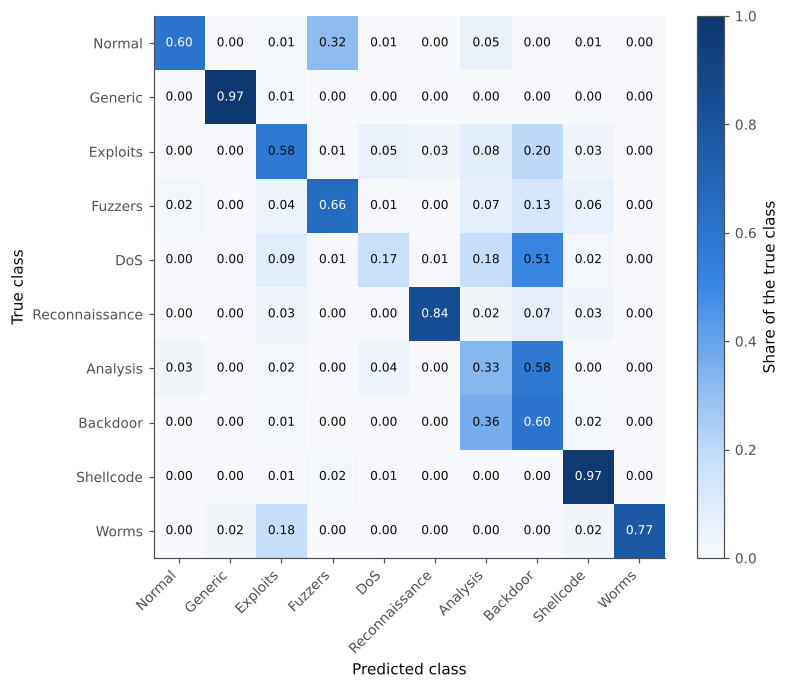

In [6]:
cm = test_cm[best]
fig, ax = plt.subplots(figsize=(7.5, 6.4))
image = heatmap(ax, cm / cm.sum(axis=1, keepdims=True), SEQUENTIAL, 0, 1, xlabels=CLASS_ORDER, ylabels=CLASS_ORDER)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
fig.colorbar(image, ax=ax, label="Share of the true class")
save(fig, f"03_test_confusion_{best}.png")
plt.show()

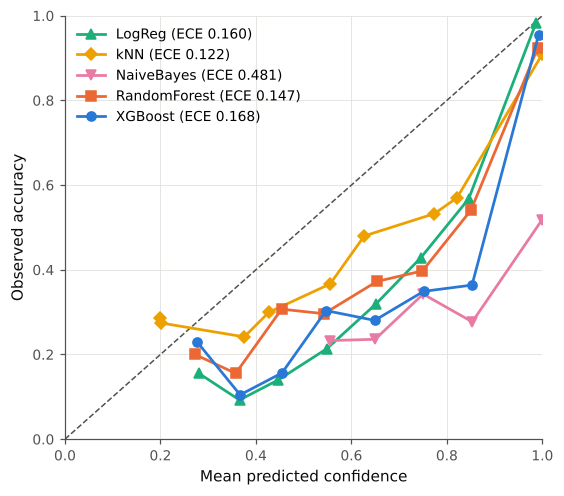

In [7]:
edges = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot([0, 1], [0, 1], color=TEXT_MUTED, linestyle="--", linewidth=1)
for name in [m for m in MODEL_NAMES if m != "Dummy"]:
    confidence = test_proba[name].max(axis=1)
    correct = test_proba[name].argmax(axis=1) == y_test
    bins = np.clip(np.digitize(confidence, edges[1:-1]), 0, 9)
    points = [(confidence[bins == b].mean(), correct[bins == b].mean()) for b in range(10) if (bins == b).sum() >= 50]
    ax.plot(*zip(*points), marker=MODEL_MARKERS[name], color=MODEL_COLORS[name],
            label=f"{name} (ECE {test_scores.loc[name, 'ece']:.3f})")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean predicted confidence")
ax.set_ylabel("Observed accuracy")
ax.legend(loc="upper left")
save(fig, "03_calibration.png")
plt.show()

In [8]:
X_all, y_all = split_X_y(train)
all_folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED).split(X_all, y_all)
with_duplicates = pd.DataFrame([fit_evaluate(Model(best, params[best]), X_all.iloc[tr], y_all[tr], X_all.iloc[va], y_all[va])[0]
                                for tr, va in all_folds])
with_duplicates_test = fit_evaluate(Model(best, params[best]), X_all, y_all, X_test, y_test)[0]
deduplicated_cv = cv[cv["model"] == best]
sensitivity = pd.DataFrame({
    "training_records": [len(y), len(y_all)],
    "cv_macro_f1_mean": [deduplicated_cv["macro_f1"].mean(), with_duplicates["macro_f1"].mean()],
    "cv_macro_f1_std": [deduplicated_cv["macro_f1"].std(), with_duplicates["macro_f1"].std()],
    "test_macro_f1": [test_scores.loc[best, "macro_f1"], with_duplicates_test["macro_f1"]],
}, index=["deduplicated", "with_duplicates"])
sensitivity.to_csv(RESULTS_DIR / "03_duplicate_sensitivity.csv")
sensitivity.round(4)

,training_records,cv_macro_f1_mean,cv_macro_f1_std,test_macro_f1
deduplicated,107740,0.6284,0.0138,0.5152
with_duplicates,175341,0.6088,0.0120,0.5117
